In [1]:
import torch
import torch.nn as nn
import math
from torch.autograd import Variable
from torch.utils.data import DataLoader, Dataset
from torch import optim
from torch import Tensor

import pickle
import numpy as np

import torchvision.transforms as transforms
from torchvision.models import vgg16, efficientnet_v2_s, resnet18
from PIL import Image
import matplotlib.pyplot as plt


from nltk.translate.bleu_score import corpus_bleu
from nltk.translate.bleu_score import SmoothingFunction

from evaluate import load

/home/nnyamkin/.local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
class PositionalEncoding(nn.Module):

    def __init__(self, d_model: int, dropout: float = 0.1, max_len: int = 10):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, 1, d_model)
        pe[:, 0, 0::2] = torch.sin(position * div_term)
        pe[:, 0, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe)

    def forward(self, x: Tensor) -> Tensor:
        """
        Arguments:
            x: Tensor, shape ``[seq_len, batch_size, embedding_dim]``
        """
        x = x + self.pe[:x.size(0)]
        return self.dropout(x)

#### PositionalEncoding

In [3]:
# class PositionalEncoding(nn.Module):
#   def __init__(self, embedding_dim, seq_len, dropout = 0.1):
#     super(PositionalEncoding, self).__init__()
#     self.embedding_dim = embedding_dim
#     self.seq_len = seq_len
#     self.dropout = nn.Dropout(dropout)

#     positional_encoding_vectors = torch.zeros(seq_len, embedding_dim)

#     for t in range(seq_len):
#       for i in range(0, embedding_dim, 2):
#         positional_encoding_vectors[t, i] = math.sin(t / (10000 ** (2*i / embedding_dim)))
#         positional_encoding_vectors[t, i+1] = math.cos(t / (10000 ** ((2*i +1) / embedding_dim)))

#     positional_encoding_vectors = positional_encoding_vectors.unsqueeze(0)

#     # register_buffer => Tensor which is not a parameter, but should be part of the modules state.
#     # Used for tensors that need to be on the same device as the module.
#     # persistent=False tells PyTorch to not add the buffer to the state dict (e.g. when we save the model)
#     self.register_buffer('positional_encoding_vectors', positional_encoding_vectors, persistent=False)


#   def forward(self, x):

#     # это нужно для того случая, если длина последовательности переменная
#     # seq_length = x.size(1)
#     # positional_encoding_vectors = Variable(self.positional_encoding_vectors[:, :seq_length], requires_grad=False).to(x.device)

#     positional_encoding_vectors = Variable(self.positional_encoding_vectors, requires_grad=False).to(x.device)

#     # РАЗМЕРНОСТЬ x [batch_size, seq_len, emb_dim]
#     # РАЗМЕРНОСТЬ positional_encoding_vectors [seq_len, emb_dim]
#     # Добавляем информацию о позиции в эмбеддинги последовательностей батча
#     x = x + positional_encoding_vectors

#     # x = self.dropout(x)
#     return x

In [4]:
# Определим параметры
embedding_dim = 512  # Размерность эмбеддингов
seq_len = 10  # Максимальная длина последовательности
batch_size = 32  # Размер батча

# Создадим случайные эмбеддинги для входных данных
x = torch.randn(seq_len, batch_size, embedding_dim)
print(x.shape)

# Создадим экземпляр класса PositionalEncoding
pos_encoding = PositionalEncoding(embedding_dim)

# Применим позиционное кодирование к эмбеддингам
x_with_pos_encoding = pos_encoding(x)

# Выведем размеры входных и выходных тензоров
print("Размеры входного тензора x:", x.shape)
print("Размеры выходного тензора x_with_pos_encoding:", x_with_pos_encoding.shape)

torch.Size([10, 32, 512])
Размеры входного тензора x: torch.Size([10, 32, 512])
Размеры выходного тензора x_with_pos_encoding: torch.Size([10, 32, 512])


In [5]:
# Определим параметры
embedding_dim = 2  # Размерность эмбеддингов
seq_len = 5  # Максимальная длина последовательности
batch_size = 3  # Размер батча

# Создадим экземпляр класса PositionalEncoding
pos_encoding = PositionalEncoding(embedding_dim)

# Создадим случайные эмбеддинги для входных данных
x = torch.randint(10, (seq_len, batch_size, embedding_dim))
x

tensor([[[6, 0],
         [7, 9],
         [0, 8]],

        [[6, 6],
         [0, 7],
         [0, 1]],

        [[9, 3],
         [9, 9],
         [5, 1]],

        [[4, 7],
         [9, 7],
         [9, 0]],

        [[2, 2],
         [9, 8],
         [1, 5]]])

In [6]:
# Применим позиционное кодирование к эмбеддингам
x_with_pos_encoding = pos_encoding(x)
x_with_pos_encoding

tensor([[[ 6.6667,  1.1111],
         [ 7.7778, 11.1111],
         [ 0.0000, 10.0000]],

        [[ 7.6016,  7.2670],
         [ 0.0000,  8.3781],
         [ 0.9350,  1.7114]],

        [[11.0103,  2.8709],
         [11.0103,  9.5376],
         [ 6.5659,  0.6487]],

        [[ 4.6012,  0.0000],
         [ 0.0000,  0.0000],
         [10.1568, -1.1000]],

        [[ 1.3813,  1.4960],
         [ 9.1591,  8.1626],
         [ 0.2702,  4.8293]]])

В реализации, которую мы рассматривали, вектор positional_encoding_vectors будет одним и тем же для всех последовательностей в пределах одного батча.

Причина в том, что позиционные кодировки вычисляются один раз во время инициализации класса PositionalEncoding и сохраняются в атрибуте self.positional_encoding_vectors.

#### Dataset

In [3]:
from tokenizers import BertWordPieceTokenizer

In [4]:
# 8 целевых токенов + токен начала и конца предложения
length = 12

# инициализируем токенайзер используя сгенерированный словарь
tokenizer = BertWordPieceTokenizer('./bert-it/bert-it-vocab.txt')
tokenizer.enable_truncation(max_length = length)
tokenizer.enable_padding(length = length)

In [5]:
vocab = tokenizer.get_vocab()
# vocab

In [6]:
vocab_size = tokenizer.get_vocab_size()
vocab_size

6471

In [7]:
enc = tokenizer.encode('A woman posing for the camera, holding a pink, open umbrella and wearing a bright, floral, ruched bathing suit, by a life guard stand with lake, green trees, and a blue sky with a few clouds behind.')
enc

Encoding(num_tokens=12, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])

In [8]:
enc.ids

[2, 41, 195, 915, 346, 114, 858, 16, 220, 41, 848, 4]

In [9]:
caption_ids = [2, 41, 195, 915, 346, 114, 0, 0, 0, 0]
len(caption_ids)

10

In [10]:
def create_padding_mask(caption_ids):

    caption_ids_reversed = list(reversed(caption_ids))

    mask_reversed = torch.zeros(length, dtype = torch.bool)

    for i, id in enumerate(caption_ids_reversed):
        if id == 0:  
            mask_reversed[i] = True

    # Обратный порядок
    mask = mask_reversed.flip(0)

    return mask

In [11]:
create_padding_mask(caption_ids)

tensor([False, False, False, False, False, False, False, False,  True,  True,
         True,  True])

In [12]:
class CustomDataset(Dataset):
    def __init__(self, images, captions, tokenizer):
        self.images = images
        self.captions = captions
        self.tokenizer = tokenizer

    # возвращаю количество примеров в датасете
    def __len__(self):
        return len(self.images)

    # по индексу возвращаем словарь, содержащий описание и изображение
    def __getitem__(self, index):

        # image = self.images[index].tolist()

        # тензор изображения - РАЗМЕРНОСТЬ [1, cnn_feature_dim]
        # по индексу берем вектор изображения
        image = self.images[index]

        # по индексу возьмем первое описание для изображения
        caption = self.captions[index][0]

        # токенезируем описание, будем брать первое описание из 5 доступных
        # ['A bunch of trays that have different food.'] => [2, 41, 602, 112, 2462, 218, 1229, 681, 347, 18, 4]

        # 2 - [CLS] - начало предложения
        # 4 - [SEP] - конец предложения

        caption_ids = self.tokenizer.encode(caption).ids
        # РАЗМЕРНОСТЬ [seq_len]
        caption = torch.tensor(caption_ids)

        # Padding mask
        mask = create_padding_mask(caption_ids)

        return {'image_vector':image,
                'caption':caption,
                'padding_mask':mask}

In [14]:
# val_images = pickle.load(open('./pickle_files/resnet18_val_features.pickle','rb'))
# val_captions = pickle.load(open('./pickle_files/val_captions.pickle','rb'))

val_images = pickle.load(open('./pickle_files/VGG16_val_features.pickle','rb'))
val_captions = pickle.load(open('./pickle_files/val_captions.pickle','rb'))

data = CustomDataset(images = val_images,
                     captions = val_captions,
                     tokenizer = tokenizer)

In [15]:
data[6]['image_vector'], data[6]['caption'], data[6]['padding_mask']

(tensor([[0., 0., 0.,  ..., 0., 0., 0.]]),
 tensor([  2,  41, 357, 119,  41, 837,  16, 918, 122, 872, 119,   4]),
 tensor([False, False, False, False, False, False, False, False, False, False,
         False, False]))

In [16]:
data[6]['image_vector'].shape

torch.Size([1, 4096])

In [17]:
# Определим параметры
embedding_dim = 512  # Размерность эмбеддингов
seq_len = 10  # Максимальная длина последовательности
batch_size = 32  # Размер батча

# Создадим случайные эмбеддинги для входных данных
x = torch.randn(batch_size, seq_len, embedding_dim)

target_subsequent_mask = nn.Transformer().generate_square_subsequent_mask(x.shape[1])
target_subsequent_mask

/home/nnyamkin/miniconda3/envs/image_captioning/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

#### Decoder

In [18]:
class ImageEncoder(nn.Module):
    # embedding_dim - размерность вектора скрытого состояния
    # cnn_features_dim - размерность извлеченного CNN моделью вектора с фичами из изображения

    def __init__(self,
                 embedding_dim = 512,
                 cnn_features_dim = 4096,
                 cnn_model = 'vgg16'):  # флаг использования линейного слоя в конце, 
                                        # если False, то вектор фичей изорбражения разбивается на num_image_features равных эмбеддингов

        super(ImageEncoder, self).__init__()

        self.device = 'cuda' if torch.cuda.is_available() else 'cpu'
        

        if cnn_model == 'vgg16':
            # объявление модели
            self.cnn = vgg16(weights='VGG16_Weights.IMAGENET1K_V1')

            # заменяем последний полносвязный слой на "пустышку"
            self.cnn.classifier[5] = torch.nn.Identity()  # Замена последнего слоя на Identity
            # заменяем последний полносвязный слой на "пустышку"
            self.cnn.classifier[6] = torch.nn.Identity()  # Замена последнего слоя на Identity
        
        elif cnn_model == 'efficientnet':
            self.cnn = efficientnet_v2_s(weights='EfficientNet_V2_S_Weights.DEFAULT')
            self.cnn.classifier[0] =torch.nn.Identity()
            self.cnn.classifier[1] = torch.nn.Identity()
        
        elif cnn_model == 'resnet18':
            
            self.cnn = resnet18(weights='ResNet18_Weights.DEFAULT')
            self.cnn.fc =torch.nn.Identity()
        
        else:
            raise Exception("Введите правильный тип CNN модели")

        # замораживаю параметры модели
        for parameter in self.cnn.parameters():
            parameter.requires_grad = False

        # инициализируем линейные слои
        self.linear = nn.Linear(cnn_features_dim, embedding_dim)


    def get_image_features(self, path):
        # прочитаем изображение
        image = Image.open(path)

        # инициализируем этапы предобработки датасета изображений
        transform = transforms.Compose([
                                      #приводим к нужному размеру
                                      transforms.Resize((224,224)),
                                      # превращаем изображение в тензор
                                      transforms.ToTensor(),
                                      # transforms.PILToTensor(),
                                      # Зачем нужна нормализация???
                                      transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                                           std=[0.229, 0.224, 0.225])])
        # Применяем transform к изображению
        transformed_image = transform(image).unsqueeze(0).to(self.device)

        # извлечем фичи из изображения
        # image_feature_vector - РАЗМЕРНОСТЬ [1, 4096]
        image_feature_vector = self.cnn(transformed_image)

        # output - РАЗМЕРНОСТЬ [batch_size, num_image_features, embedding_dim]
        return self.forward(image_feature_vector)

    def forward(self, image_feature_vector):
        # ВХОД
        # image_vectors - РАЗМЕРНОСТЬ [batch_size, cnn_features_dim], тензор, содержащий тензоры признаков для изображений в батче
        # меняем dtype из float64 в float32
        image_feature_vector = image_feature_vector.float()

        batch_size = image_feature_vector.shape[0]

        # ВЫХОДЫ
        output = self.linear(image_feature_vector)
        output = output.unsqueeze(1)
        
        # Нормализация output с использованием L2-нормы
        # output_norm = torch.norm(output, p=2, dim=2, keepdim=True)
        # output = output / output_norm
        
        # Нормализация output для эквивалентности с эмбеддингами
        output_mean = torch.mean(output, dim=2, keepdim=True)
        output_std = torch.std(output, dim=2, keepdim=True)
        output = (output - output_mean) / output_std

        # output - РАЗМЕРНОСТЬ [batch_size, num_image_features, embedding_dim]
        return output

In [19]:
data[6]['image_vector'].shape

torch.Size([1, 4096])

In [22]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

encoder = ImageEncoder(embedding_dim = 512,
                       cnn_features_dim = 4096,
                       cnn_model = 'vgg16').to(device)
# data[6]['image_vector'].shape
output = encoder.forward(data[6]['image_vector'].to(device))
output.shape

torch.Size([1, 1, 512])

In [23]:
output = encoder.get_image_features('./test images/cat_1.jpg')
output.shape

torch.Size([1, 1, 512])

In [24]:
class TransformerDecoder(nn.Module):
    
    def __init__(self,
               embedding_dim,
               seq_len,
               vocab_size,
               n_head,
               fc_dim,
               dropout,
               num_decoder_layers
               ):
        
        super(TransformerDecoder, self).__init__()

        self.device = 'cuda' if torch.cuda.is_available() else 'cpu'
        self.seq_len = seq_len

        # x.shape[1] = seq_len
        # РАЗМЕРНОСТЬ target_subsequent_mask [seq_len, seq_len]

        # Создание верхнетреугольной маски для декодера
        # self.target_subsequent_mask = torch.triu(torch.ones((seq_len, seq_len), device=self.device), diagonal=1).bool()
        self.target_subsequent_mask = nn.Transformer().generate_square_subsequent_mask(seq_len).to(self.device)

        self.embedding_dim = embedding_dim

        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        # self.positional_encoding = PositionalEncoding(embedding_dim, seq_len)
        self.positional_encoding = PositionalEncoding(d_model = embedding_dim, max_len = seq_len)

        decoder_layer = nn.TransformerDecoderLayer(d_model = embedding_dim,
                                                   nhead = n_head,
                                                   dim_feedforward = fc_dim,
                                                   dropout = dropout,
                                                   batch_first=False)

        self.decoder = nn.TransformerDecoder(decoder_layer, num_decoder_layers)

        self.linear = nn.Linear(embedding_dim, vocab_size)

        self.softmax = nn.Softmax(dim = -1)
        


    def forward(self,
              caption_ids,
              image_features,
              target_pad_mask
              ):

        # РАЗМЕРНОСТЬ caption_ids [batch_size, seq_len]
        # РАЗМЕРНОСТЬ image_features [batch_size, num_image_features, embedding_dim]
        # РАЗМЕРНОСТЬ target_pad_mask [batch_size, seq_len]

        # РАЗМЕРНОСТЬ x [batch_size, seq_len, emb_dim]
        x = self.embedding(caption_ids)

        # РАЗМЕРНОСТЬ x [seq_len, batch_size, emb_dim]
        x = x.permute(1,0,2)

        # РАЗМЕРНОСТЬ image_features [num_image_features, batch_size, emb_dim]
        image_features = image_features.permute(1,0,2)

        # РАЗМЕРНОСТЬ x [seq_len, batch_size, emb_dim]
        x = self.positional_encoding.forward(x)

        # РАЗМЕРНОСТЬ x [seq_len, batch_size, emb_dim]
        x = self.decoder(tgt = x,
                         memory = image_features,
                         tgt_mask=self.target_subsequent_mask,
                         tgt_key_padding_mask=target_pad_mask,
                         )

        # output - РАЗМЕРНОСТЬ [seq_len, batch_size, vocab_size]
        output = self.linear(x)
        # output = self.softmax(output)

        # output - РАЗМЕРНОСТЬ [seq_len, batch_size, vocab_size]
        return output

In [25]:
# Параметры
embedding_dim = 512
seq_len = 5

vocab_size = vocab_size
n_head = 8
fc_dim = 2048
dropout = 0.1
num_decoder_layers = 6
device = 'cuda' if torch.cuda.is_available() else 'cpu'
batch_size = 2
num_image_features = 8

# Входные данные
caption_ids = torch.randint(0, vocab_size, (batch_size, seq_len)).to(device)
image_features = torch.randn(batch_size, num_image_features, embedding_dim).to(device)
target_pad_mask = torch.tensor([[False, False, False, False, False],
                                [False, False, False, True, True]]).to(device)

# Создаем экземпляр TransformerDecoder
decoder = TransformerDecoder(embedding_dim,
                             seq_len,
                             vocab_size,
                             n_head,
                             fc_dim,
                             dropout,
                             num_decoder_layers).to(device)

# Проходим forward()
output = decoder.forward(caption_ids, image_features, target_pad_mask)
output.shape

/home/nnyamkin/miniconda3/envs/image_captioning/lib/python3.11/site-packages/torch/nn/functional.py:5109: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(


torch.Size([5, 2, 6471])

In [26]:
output

tensor([[[ 0.9807,  0.1030, -1.5954,  ..., -0.3322,  0.2470, -0.2526],
         [ 0.3474, -0.2923, -0.6379,  ...,  1.0236, -0.4300,  1.0632]],

        [[ 1.3287, -0.1078, -1.4133,  ..., -0.1483, -0.2631, -0.0958],
         [ 0.3066, -0.7956, -0.7466,  ...,  0.9398, -0.5404,  0.1443]],

        [[ 1.0615,  0.0714, -1.1848,  ...,  0.3397, -0.6863, -0.0414],
         [ 0.4156, -0.3143, -0.8131,  ...,  0.7383, -0.7836,  0.7816]],

        [[ 1.3033,  0.0498, -1.4035,  ...,  0.0035, -0.8414,  0.5442],
         [ 0.4715, -0.2695, -0.3234,  ...,  0.5711, -0.9735,  0.1595]],

        [[ 0.7465, -0.4908, -1.4083,  ...,  0.3512, -0.7774,  1.0916],
         [ 0.2311, -0.4629, -0.7587,  ...,  0.7121, -1.0124,  0.6812]]],
       device='cuda:0', grad_fn=<ViewBackward0>)

In [27]:
output[0][0].sum()

tensor(54.7777, device='cuda:0', grad_fn=<SumBackward0>)

In [28]:
class ImageCaption(torch.nn.Module):
    def __init__(self,
                 encoder,
                 decoder,
                 seq_len
                 ):

        super(ImageCaption, self).__init__()

        self.device = 'cuda' if torch.cuda.is_available() else 'cpu'

        self.encoder = encoder
        self.decoder = decoder
        self.seq_len = seq_len

    def forward(self,
                image_vectors,
                caption_ids,
                target_pad_mask
               ):
        # image_vectors - РАЗМЕРНОСТЬ [batch_size, 4096]
        # caption_ids - РАЗМЕРНОСТЬ [batch_size, seq_len]
        # target_pad_mask - РАЗМЕРНОСТЬ [batch_size, seq_len]

        # image_features - РАЗМЕРНОСТЬ [batch_size, num_image_features, embedding_dim]
        image_features = self.encoder.forward(image_vectors)

        predicted_sequences = self.decoder.forward(caption_ids = caption_ids,
                                                   image_features = image_features,
                                                   target_pad_mask = target_pad_mask)

        # predicted_sequences - РАЗМЕРНОСТЬ [seq_len, batch_size, vocab_size]
        return predicted_sequences


    def generate_one_caption(self, path):
        
        

        # image_features - РАЗМЕРНОСТЬ [batch_size, num_image_features, embedding_dim]
        image_features = self.encoder.get_image_features(path)

        # predicted_sequence = [4, 0, 0, 0, 0, 0, 0, 0, 0, 0]
        predicted_caption_ids = [tokenizer.token_to_id('[CLS]')] + [tokenizer.token_to_id('[PAD]')] * (self.seq_len - 1)

        for i in range(self.seq_len - 1):
            # predicted_sequence - РАЗМЕРНОСТЬ [batch_size, seq_len]
            predicted_sequence = torch.LongTensor(predicted_caption_ids).unsqueeze(0).to(self.device)

            # target_pad_mask - РАЗМЕРНОСТЬ [batch_size, seq_len]
            target_pad_mask = torch.zeros((1, self.seq_len), dtype=torch.bool).to(self.device)

            target_pad_mask[:, i + 1 :] = True

            # тензор с распределением вероятностей следующего слова
            # output - РАЗМЕРНОСТЬ [seq_len, batch_size, vocab_size], тензор, содержащий распределение вероятностей токенов на шаге t+1.
            output = self.decoder.forward(predicted_sequence, image_features, target_pad_mask)

            # токен с наибольшей вероятностью в этом векторе, будет следующим в последовательности
            # output = output.argmax(dim=-1)[:, i].item()
            output = output.argmax(dim=-1)[i, :].item()

            predicted_caption_ids[i + 1] = output
            # print(predicted_sequence)
            # print(predicted_caption_ids)
            # print()



        # у токенайзера возьмем id токена, означающего конец описания
        EOS_IDX = tokenizer.token_to_id('[SEP]')

        # predicted_sequence = predicted_sequence.squeeze()
        predicted_sequence = torch.LongTensor(predicted_caption_ids)

        # возьмем последовательность токенов и сгенерируем описание  [100, 23423, 321, 242, ..., 101]
        for t in predicted_sequence:
            
            if t.item() != EOS_IDX:
                print(tokenizer.id_to_token(t.item()), end = ' ')
            else:
                break

In [33]:
# Параметры
batch_size = 2
seq_len = 12
embedding_dim = 512
cnn_features_dim = 4096
cnn_model = 'vgg16'
vocab_size = vocab_size
n_head = 8
fc_dim = 2048
dropout = 0.1
num_decoder_layers = 6
device = 'cuda' if torch.cuda.is_available() else 'cpu'


encoder = ImageEncoder(embedding_dim = embedding_dim,
                       cnn_features_dim = cnn_features_dim,
                       cnn_model = cnn_model).to(device)

decoder = TransformerDecoder(embedding_dim,
                             seq_len,
                             vocab_size,
                             n_head,
                             fc_dim,
                             dropout,
                             num_decoder_layers).to(device)

In [34]:
model = ImageCaption(encoder,
                     decoder,
                     seq_len).to(device)

In [35]:
data[6]['image_vector'].shape, data[6]['caption'].unsqueeze(0).shape, data[6]['padding_mask'].unsqueeze(0).shape

(torch.Size([1, 4096]), torch.Size([1, 12]), torch.Size([1, 12]))

In [36]:
output = model.forward(data[6]['image_vector'].to(device), data[6]['caption'].unsqueeze(0).to(device), data[6]['padding_mask'].unsqueeze(0).to(device))
output.shape

torch.Size([12, 1, 6471])

In [37]:
output

tensor([[[ 0.2770,  0.0852,  0.0613,  ..., -0.4920,  0.1895,  0.0144]],

        [[ 0.2799,  0.0093,  0.0342,  ..., -0.2502,  0.1076,  0.0672]],

        [[ 0.2078, -0.0366,  0.1323,  ..., -0.4158, -0.2646, -0.0963]],

        ...,

        [[ 0.2589,  0.3779,  0.2096,  ..., -0.5890, -0.2930,  0.0637]],

        [[ 0.2949,  0.0924,  0.0907,  ..., -0.5066,  0.0719,  0.1257]],

        [[ 0.0803,  0.1094,  0.2745,  ..., -0.2596, -0.0314, -0.0473]]],
       device='cuda:0', grad_fn=<ViewBackward0>)

In [38]:
output[4][0].sum()

tensor(-28.8845, device='cuda:0', grad_fn=<SumBackward0>)

In [39]:
def plot_image(path):
    # прочитаем изображение
    image = Image.open(path)  
    image = np.array(image)

    plt.imshow(image)

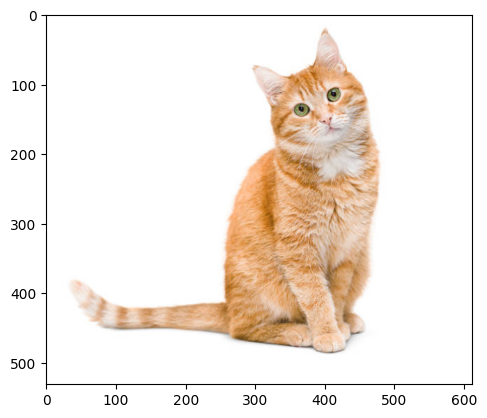

In [40]:
plot_image('./test images/cat_1.jpg')

In [41]:
model.generate_one_caption('./test images/cat_1.jpg')

[CLS] ##cakes pale pale pale pale ##cakes pale pale pale ##cakes pale 

In [42]:
# функция для генерации одного описания
def get_image_caption(path):
    # отобразим изображение
    plot_image(path)

    # сгенерируем описание используя метод generate_caption  ImageCaption
    model.generate_one_caption(path)

[CLS] pale pale pale pale ##child pale pale submerged pale pale pale 

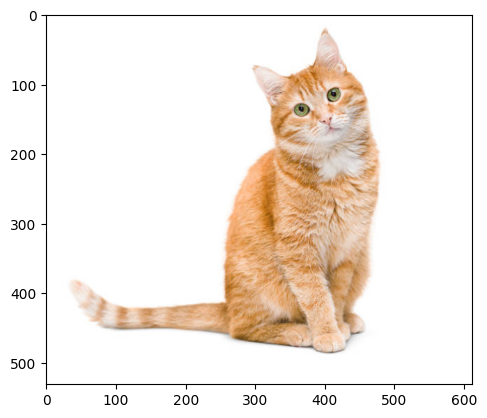

In [43]:
get_image_caption('./test images/cat_1.jpg')

In [44]:
bertscore = load("bertscore")

def metrics(predicted_sequences, target_sequences):
    # выбираем argmax для каждого массива размерности vocab_size в массиве seq_len
    # массив предсказанных индексов токенов последвоательности
    
    # predicted_sequences - РАЗМЕРНОСТЬ [seq_len - 1, batch_size, vocab_size]
    # target_sequences - РАЗМЕРНОСТЬ [seq_len - 1, batch_size]

    # [seq_len - 1, batch_size]
    predict = torch.argmax(predicted_sequences, -1)

    predicted_tokens = []
    predicted_tokens_for_bert_score = []
    
    target_tokens = []

    for i in range(predict.shape[1]):
        
        predict_token_id = predict[:, i].tolist()

        predict_token = tokenizer.decode(predict_token_id)

        target_token_id = target_sequences[:,i].tolist()

        target_token = tokenizer.decode(target_token_id)

        predicted_tokens.append([predict_token])
        
        predicted_tokens_for_bert_score.append(predict_token)

        target_tokens.append(target_token)
    
    bleu_1 = corpus_bleu(predicted_tokens, target_tokens, weights = (1.0, 0, 0, 0))
    bleu_2 = corpus_bleu(predicted_tokens, target_tokens, weights = (0.5, 0.5, 0, 0))
    bleu_3 = corpus_bleu(predicted_tokens, target_tokens, weights = (1.0/3.0, 1.0/3.0, 1.0/3.0, 0))
    bleu_4 = corpus_bleu(predicted_tokens, target_tokens, weights = (0.25, 0.25, 0.25, 0.25), smoothing_function = SmoothingFunction().method1)
    
    bert_score = bertscore.compute(predictions=predicted_tokens_for_bert_score, 
                                   references=target_tokens, 
                                   lang = 'en',
                                   model_type="roberta-large")
    
    
    precision = np.array(bert_score['precision']).mean()
    recall = np.array(bert_score['recall']).mean()
    f1 = np.array(bert_score['f1']).mean()
    
    return {'bleu_1': bleu_1, 
            'bleu_2':bleu_2, 
            'bleu_3':bleu_3,
            'bleu_4':bleu_4, 
            'bert_precision': precision,
            'bert_recall': recall,
            'bert_f1': f1,
           }
    
    # return corpus_bleu(predicted_tokens, target_tokens, smoothing_function = SmoothingFunction().method1)

# Предсказанные последовательности (predicted_sequences)
predicted_sequences = torch.tensor([
    [[0.1, 0.2, 0.7], [0.3, 0.6, 0.1], [0.8, 0.1, 0.1]],
    [[0.2, 0.4, 0.4], [0.7, 0.2, 0.1], [0.1, 0.8, 0.1]]
]).transpose(0, 1)

# print(predicted_sequences.shape)

# Целевые последовательности (target_sequences)
target_sequences = torch.tensor([
    [2, 1, 0],
    [1, 0, 1]
]).transpose(0, 1)

# print(target_sequences.shape)

metrics_score = metrics(predicted_sequences, target_sequences)
print(f"BLEU score: {metrics_score}")

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


BLEU score: {'bleu_1': 0, 'bleu_2': 0, 'bleu_3': 0, 'bleu_4': 0, 'bert_precision': 0.0, 'bert_recall': 0.0, 'bert_f1': 0.0}


In [52]:
def train(model, dataloader, optimizer, criterion):

    model.train()

    epoch_loss = 0
    bleu_1 = 0
    bleu_2 = 0
    bleu_3 = 0
    bleu_4 = 0
    bert_precision = 0
    bert_recall = 0
    bert_f1 = 0

    for batch in dataloader:

        # [batch_size, cnn_features_dim]
        image_features = batch['image_vector'].squeeze().to(device)

        # [batch_size, seq_len]
        target_caption_ids = batch['caption'].to(device)

        # [batch_size, seq_len]
        target_pad_masks = batch['padding_mask'].to(device)

        optimizer.zero_grad()

        # predicted_caption_ids - РАЗМЕРНОСТЬ [seq_len - 1, batch_size, vocab_size]
        # [:, :-1] - потому что не подаём токен <eos> на вход декодеру
        predicted_caption_ids = model.forward(image_features, target_caption_ids[:, :-1], target_pad_masks[:, :-1])

        # Транспонируем тензор (нужно привести в такой формат для корректного подсчета cross entropy loss)
        # target_sequences - РАЗМЕРНОСТЬ[seq_len, batch_size]
        target_caption_ids = target_caption_ids.transpose(0, 1)

        metrics_score = metrics(predicted_caption_ids, target_caption_ids[1:])
        
        bleu_1 += metrics_score['bleu_1']
        bleu_2 += metrics_score['bleu_2']
        bleu_3 += metrics_score['bleu_3']
        bleu_4 += metrics_score['bleu_4']
        
        bert_precision += metrics_score['bert_precision']
        bert_recall += metrics_score['bert_recall']
        bert_f1 += metrics_score['bert_f1']
        
        # сделаем необходимые решейпы для подачи данных в функцию потерь, не будем учитывать первые токены описаний
        predict_dim = predicted_caption_ids.shape[-1]

        # predicted_caption_ids - РАЗМЕРНОСТЬ [(seq_len - 1) * batch_size, vocab_size]
        predicted_caption_ids = predicted_caption_ids.view(-1, predict_dim).to(device)

        # target_caption_ids - РАЗМЕРНОСТЬ [(seq_len - 1) * batch_size]
        target_caption_ids = target_caption_ids[1:].reshape(-1)

        loss = criterion(predicted_caption_ids, target_caption_ids)
        # print(loss)

        loss.backward()

        optimizer.step()

        epoch_loss += loss.item()

    # считаем средие значения ошибки и метрик за эпоху
    
    train_loss = round((epoch_loss / len(dataloader)), 3)
    # train_loss = (epoch_loss / len(dataloader))
    # print(train_loss)

    bleu_1_mean = round((bleu_1 / len(dataloader)), 3) * 100
    bleu_2_mean = round((bleu_2 / len(dataloader)), 3) * 100
    bleu_3_mean = round((bleu_3 / len(dataloader)), 3) * 100
    bleu_4_mean = round((bleu_4 / len(dataloader)), 3) * 100
    
    bert_precision_mean = round((bert_precision / len(dataloader)), 3)
    bert_recall_mean = round((bert_recall / len(dataloader)), 3)
    bert_f1_mean = round((bert_f1 / len(dataloader)), 3)

    return {'train_loss':train_loss,
           'bleu_1_mean':bleu_1_mean,
           'bleu_2_mean': bleu_2_mean,
           'bleu_3_mean': bleu_3_mean,
           'bleu_4_mean':bleu_4_mean,
           'bert_precision_mean':bert_precision_mean,
           'bert_recall_mean':bert_recall_mean,
           'bert_f1_mean':bert_f1_mean
           }
    
    # return train_loss, bleu_4_mean

In [53]:
def evaluate(model, dataloader, criterion):
    
    model.eval()
    epoch_loss = 0
    
    bleu_1 = 0
    bleu_2 = 0
    bleu_3 = 0
    bleu_4 = 0
    bert_precision = 0
    bert_recall = 0
    bert_f1 = 0
    
    with torch.no_grad():
        
        for batch in dataloader:

            # [batch_size, cnn_features_dim]
            image_features = batch['image_vector'].squeeze().to(device)

            # [batch_size, seq_len]
            target_caption_ids = batch['caption'].to(device)

            # [batch_size, seq_len]
            target_pad_masks = batch['padding_mask'].to(device)
            
            # predicted_sequences - РАЗМЕРНОСТЬ [seq_len, batch_size, vocab_size]
            predicted_caption_ids = model.forward(image_features, target_caption_ids[:, :-1], target_pad_masks[:, :-1])

            # Транспонируем тензор (нужно привести в такой формат для корректного подсчета cross entropy loss)
            # target_sequences - РАЗМЕРНОСТЬ[seq_len, batch_size]
            target_caption_ids = target_caption_ids.transpose(0, 1)

            metrics_score = metrics(predicted_caption_ids, target_caption_ids[1:])
        
            bleu_1 += metrics_score['bleu_1']
            bleu_2 += metrics_score['bleu_2']
            bleu_3 += metrics_score['bleu_3']
            bleu_4 += metrics_score['bleu_4']

            bert_precision += metrics_score['bert_precision']
            bert_recall += metrics_score['bert_recall']
            bert_f1 += metrics_score['bert_f1']

            # сделаем необходимые решейпы для подачи данных в функцию потерь, не будем учитывать первые токены описаний
            predict_dim = predicted_caption_ids.shape[-1]

            # predicted_caption_ids - РАЗМЕРНОСТЬ [(seq_len - 1) * batch_size, vocab_size]
            predicted_caption_ids = predicted_caption_ids.view(-1, predict_dim).to(device)

            # target_caption_ids - РАЗМЕРНОСТЬ [(seq_len - 1) * batch_size]
            target_caption_ids = target_caption_ids[1:].reshape(-1)

            loss = criterion(predicted_caption_ids, target_caption_ids)

            epoch_loss += loss.item()
        
    valid_loss = round((epoch_loss / len(dataloader)), 3)
    
    bleu_1_mean = round((bleu_1 / len(dataloader)), 3) * 100
    bleu_2_mean = round((bleu_2 / len(dataloader)), 3) * 100
    bleu_3_mean = round((bleu_3 / len(dataloader)), 3) * 100
    bleu_4_mean = round((bleu_4 / len(dataloader)), 3) * 100
    
    bert_precision_mean = round((bert_precision / len(dataloader)), 3)
    bert_recall_mean = round((bert_recall / len(dataloader)), 3)
    bert_f1_mean = round((bert_f1 / len(dataloader)), 3)
    
    return {'val_loss':valid_loss,
           'bleu_1_mean':bleu_1_mean,
           'bleu_2_mean': bleu_2_mean,
           'bleu_3_mean': bleu_3_mean,
           'bleu_4_mean':bleu_4_mean,
           'bert_precision_mean':bert_precision_mean,
           'bert_recall_mean':bert_recall_mean,
           'bert_f1_mean':bert_f1_mean
           }
    
    # return valid_loss, bleu_4_mean

In [307]:
# Параметры
seq_len = 11
batch_size = 256
embedding_dim = 512
cnn_features_dim = 4096
cnn_model = 'vgg16'
vocab_size = vocab_size
n_head = 8
fc_dim = 2048
dropout = 0.1
num_decoder_layers = 6
device = 'cuda' if torch.cuda.is_available() else 'cpu'
num_epochs = 40
# lr = 0.1



encoder = ImageEncoder(embedding_dim = embedding_dim,
                       cnn_features_dim = cnn_features_dim,
                       cnn_model = cnn_model).to(device)

decoder = TransformerDecoder(embedding_dim,
                             seq_len,
                             vocab_size,
                             n_head,
                             fc_dim,
                             dropout,
                             num_decoder_layers).to(device)

model = ImageCaption(encoder,
                     decoder,
                     seq_len).to(device)

In [55]:
train_images = pickle.load(open('./pickle_files/VGG16_train_features.pickle','rb'))
# train_images = pickle.load(open('./pickle_files/resnet18_train_features.pickle','rb'))
train_captions = pickle.load(open('./pickle_files/train_captions.pickle','rb'))


val_images = pickle.load(open('./pickle_files/VGG16_val_features.pickle','rb'))
# val_images = pickle.load(open('./pickle_files/resnet18_val_features.pickle','rb'))
val_captions = pickle.load(open('./pickle_files/val_captions.pickle','rb'))

In [308]:
train_data = CustomDataset(images = train_images,
                           captions = train_captions,
                           tokenizer = tokenizer)




val_data = CustomDataset(images = val_images,
                         captions = val_captions,
                         tokenizer = tokenizer)

train_loader = DataLoader(data,
                          batch_size = batch_size,
                          shuffle = False,          # не перемешиваем картинки меду собой в батче
                          drop_last = True)         # удаляем последний пакет данных, если его размер меньше указанного

val_loader = DataLoader(val_data, 
                        batch_size = batch_size,
                        shuffle = False,           # не перемешиваем картинки меду собой в батче
                        drop_last = True)           # удаляем последний пакет данных, если его размер меньше указанного

In [309]:
PAD_IDX = tokenizer.token_to_id('[PAD]')

optimizer = optim.Adam(model.parameters(), lr=0.0001)

criterion = nn.CrossEntropyLoss(ignore_index = PAD_IDX)

In [310]:
# Создайте экземпляр модели
# Загрузите веса модели из файла

# model.load_state_dict(torch.load('./imgcap_best_bleu.pth'))

In [311]:
from tqdm import tqdm
import time


best_bleu = 20

val_losses = []
val_bleu_1 = []
val_bleu_2 = []
val_bleu_3 = []
val_bleu_4 = []
val_bert_precision = []
val_bert_recall = []
val_bert_f1 = []

start_time = time.time()
for epoch in tqdm(range(num_epochs)):
    
    train_metrcics = train(model, train_loader, optimizer, criterion)
    
    train_loss = train_metrcics['train_loss']
    train_bleu_1_mean = train_metrcics['bleu_1_mean']
    train_bleu_2_mean = train_metrcics['bleu_2_mean']
    train_bleu_3_mean = train_metrcics['bleu_3_mean']
    train_bleu_4_mean = train_metrcics['bleu_4_mean']
    train_bert_precision_mean = train_metrcics['bert_precision_mean']
    train_bert_recall_mean = train_metrcics['bert_recall_mean'] 
    train_bert_f1_mean = train_metrcics['bert_f1_mean'] 
    
    
    val_metrcics = evaluate(model, val_loader, criterion)
    
    val_loss = val_metrcics['val_loss']
    val_bleu_1_mean = val_metrcics['bleu_1_mean']
    val_bleu_2_mean = val_metrcics['bleu_2_mean']
    val_bleu_3_mean = val_metrcics['bleu_3_mean']
    val_bleu_4_mean = val_metrcics['bleu_4_mean']
    val_bert_precision_mean = val_metrcics['bert_precision_mean']
    val_bert_recall_mean = val_metrcics['bert_recall_mean'] 
    val_bert_f1_mean = val_metrcics['bert_f1_mean'] 
    
    print(f'''
              ===================================  
              Epoch: {epoch + 1}
            
              TRAIN
    
              TRAIN LOSS: {train_loss}  
              
              BLEU 1: {train_bleu_1_mean}
              
              BLEU 2: {train_bleu_2_mean}
              
              BLEU 3: {train_bleu_3_mean}          
              
              BLEU 4: {train_bleu_4_mean}
              
              BERT PRECISION: {train_bert_precision_mean}
              
              BERT RECALL: {train_bert_recall_mean}
              
              BERT F1: {train_bert_f1_mean}
              
              ----------------------------------
              
              VALIDATION
              
              VAL LOSS: {val_loss}
              
              BLEU 1: {val_bleu_1_mean}
              
              BLEU 2: {val_bleu_2_mean}
              
              BLEU 3: {val_bleu_3_mean}
              
              BLEU 4: {val_bleu_4_mean}
              
              BERT PRECISION: {val_bert_precision_mean}
              
              BERT RECALL: {val_bert_recall_mean}
              
              BERT F1: {val_bert_f1_mean}
              =================================== 
              ''')
    
    
    val_losses.append(val_loss)
    val_bleu_1.append(val_bleu_1_mean)
    val_bleu_2.append(val_bleu_2_mean)
    val_bleu_3.append(val_bleu_3_mean)
    val_bleu_4.append(val_bleu_4_mean)
    
    val_bert_precision.append(val_bert_precision_mean)
    val_bert_recall.append(val_bert_recall_mean)
    val_bert_f1.append(val_bert_f1_mean)
    
    # сохраним модель модель с лучшей метрикой BLEU
    if best_bleu < train_bleu_4_mean:
        best_bleu = train_bleu_4_mean
        torch.save(model.state_dict(), 'imgcap_best_bleu.pth')

end_time = time.time()

torch.save(model.state_dict(), 'imgcap_last.pth')

execution_time = (end_time - start_time) / 60
print("Время выполнения функции: ", execution_time)

  2%|▎         | 1/40 [00:15<10:10, 15.67s/it]


              Epoch: 1
            
              TRAIN
    
              TRAIN LOSS: 6.917  
              
              BLEU 1: 26.900000000000002
              
              BLEU 2: 13.200000000000001
              
              BLEU 3: 6.7          
              
              BLEU 4: 0.8999999999999999
              
              BERT PRECISION: 0.726
              
              BERT RECALL: 0.808
              
              BERT F1: 0.764
              
              ----------------------------------
              
              VALIDATION
              
              VAL LOSS: 6.183
              
              BLEU 1: 27.6
              
              BLEU 2: 13.4
              
              BLEU 3: 6.9
              
              BLEU 4: 0.8
              
              BERT PRECISION: 0.728
              
              BERT RECALL: 0.817
              
              BERT F1: 0.77
              


  5%|▌         | 2/40 [00:31<09:59, 15.79s/it]


              Epoch: 2
            
              TRAIN
    
              TRAIN LOSS: 5.874  
              
              BLEU 1: 23.799999999999997
              
              BLEU 2: 12.0
              
              BLEU 3: 6.2          
              
              BLEU 4: 0.7000000000000001
              
              BERT PRECISION: 0.74
              
              BERT RECALL: 0.815
              
              BERT F1: 0.775
              
              ----------------------------------
              
              VALIDATION
              
              VAL LOSS: 5.485
              
              BLEU 1: 5.2
              
              BLEU 2: 2.6
              
              BLEU 3: 1.4000000000000001
              
              BLEU 4: 0.2
              
              BERT PRECISION: 0.822
              
              BERT RECALL: 0.801
              
              BERT F1: 0.811
              


  8%|▊         | 3/40 [00:49<10:15, 16.63s/it]

...


              Epoch: 39
            
              TRAIN
    
              TRAIN LOSS: 1.075  
              
              BLEU 1: 84.2
              
              BLEU 2: 78.8
              
              BLEU 3: 75.2          
              
              BLEU 4: 72.39999999999999
              
              BERT PRECISION: 0.938
              
              BERT RECALL: 0.936
              
              BERT F1: 0.937
              
              ----------------------------------
              
              VALIDATION
              
              VAL LOSS: 0.872
              
              BLEU 1: 85.8
              
              BLEU 2: 81.10000000000001
              
              BLEU 3: 78.0
              
              BLEU 4: 75.6
              
              BERT PRECISION: 0.948
              
              BERT RECALL: 0.944
              
              BERT F1: 0.946
              


 98%|█████████▊| 39/40 [13:56<00:22, 22.03s/it]


              Epoch: 40
            
              TRAIN
    
              TRAIN LOSS: 1.017  
              
              BLEU 1: 84.8
              
              BLEU 2: 79.80000000000001
              
              BLEU 3: 76.4          
              
              BLEU 4: 73.8
              
              BERT PRECISION: 0.941
              
              BERT RECALL: 0.939
              
              BERT F1: 0.94
              
              ----------------------------------
              
              VALIDATION
              
              VAL LOSS: 0.858
              
              BLEU 1: 86.2
              
              BLEU 2: 81.39999999999999
              
              BLEU 3: 78.3
              
              BLEU 4: 75.9
              
              BERT PRECISION: 0.947
              
              BERT RECALL: 0.945
              
              BERT F1: 0.946
              


100%|██████████| 40/40 [14:17<00:00, 21.44s/it]


Время выполнения функции:  14.293954066435496


In [312]:
def plot_loss(epochs, loss, title):
    # Устанавливаем размер окна графика
    plt.figure(figsize =(8,6))
    # Создаем линейный график с маркерами
    plt.plot(epochs, loss, marker = 'o', markersize=4)
    # Устанавливаем подпись для оси X
    plt.xlabel('Epochs')
    # Устанавливаем подпись для оси Y
    plt.ylabel('Loss')
    # Устанавливаем заголовок графика
    plt.title(title)
    # Добавляем сетку на график
    plt.grid(True)
    # Отображаем график
    plt.show()

In [313]:
def plot_bleu(epochs, bleu_1, bleu_2, bleu_3, bleu_4, title = 'BLEU'):
    # Создаем фигуру и область для графика
    fig, ax = plt.subplots(figsize=(8, 6))
    # Строим график для train_loss
    ax.plot(epochs, bleu_1, label='BLEU 1', marker='o', markersize=4)
    # Строим график для val_loss
    ax.plot(epochs, bleu_2, label='BLEU 2', marker='o', markersize=4)
    
    ax.plot(epochs, bleu_3, label='BLEU 3', marker='o', markersize=4)
    
    ax.plot(epochs, bleu_4, label='BLEU 4', marker='o', markersize=4)
    
    # Устанавливаем подписи для осей
    ax.set_xlabel('Epoch')
    ax.set_ylabel('BLEU')
    # Устанавливаем заголовок графика
    ax.set_title(title)
    # Добавляем легенду
    ax.legend()
    # Добавляем сетку
    ax.grid(True)
    # Отображаем график
    plt.show()

In [314]:
def plot_bert_score(epochs, bert_precision, bert_recall, bert_f1, title = 'BERT Score'):
    
    # Создаем фигуру и область для графика
    fig, ax = plt.subplots(figsize=(8, 6))
    
    ax.plot(epochs, bert_precision, label='BERT Precision', marker='o', markersize=4)
    
    ax.plot(epochs, bert_recall, label='BERT Recall', marker='o', markersize=4)
    
    ax.plot(epochs, bert_f1, label='BERT F1', marker='o', markersize=4)
    
    # Устанавливаем подписи для осей
    ax.set_xlabel('Epoch')
    ax.set_ylabel('BERT Score')
    # Устанавливаем заголовок графика
    ax.set_title(title)
    # Добавляем легенду
    ax.legend()
    # Добавляем сетку
    ax.grid(True)
    # Отображаем график
    plt.show()

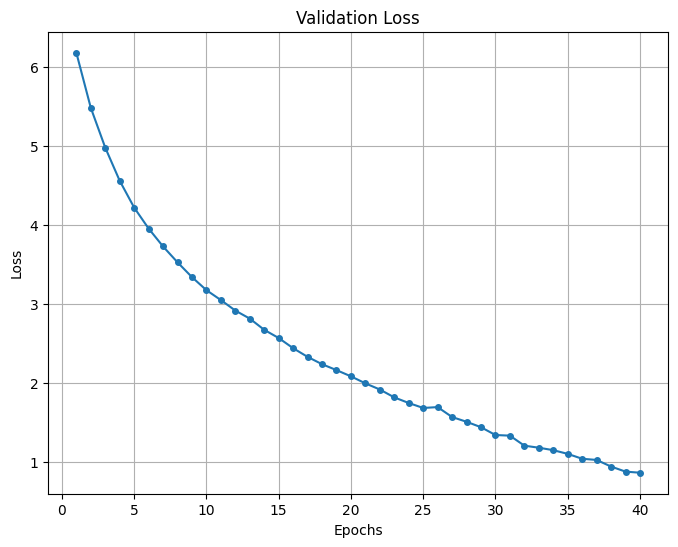

In [315]:
plot_loss(range(1, 40 + 1), val_losses, title = 'Validation Loss')

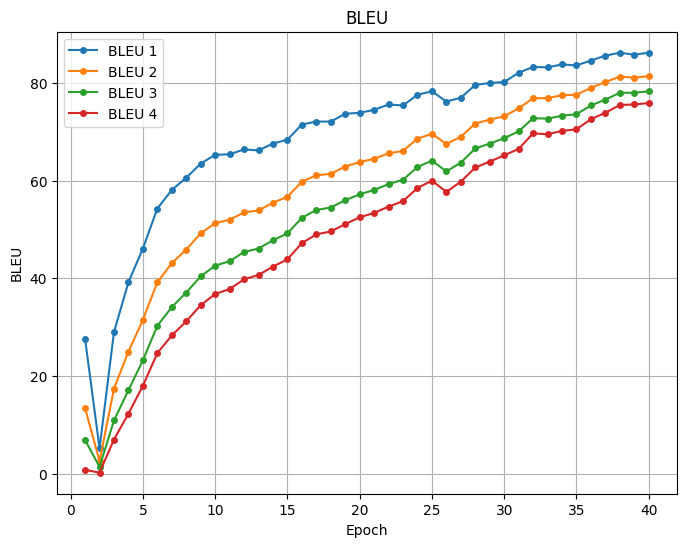

In [316]:
plot_bleu(range(1, 40 + 1), val_bleu_1, val_bleu_2, val_bleu_3, val_bleu_4)

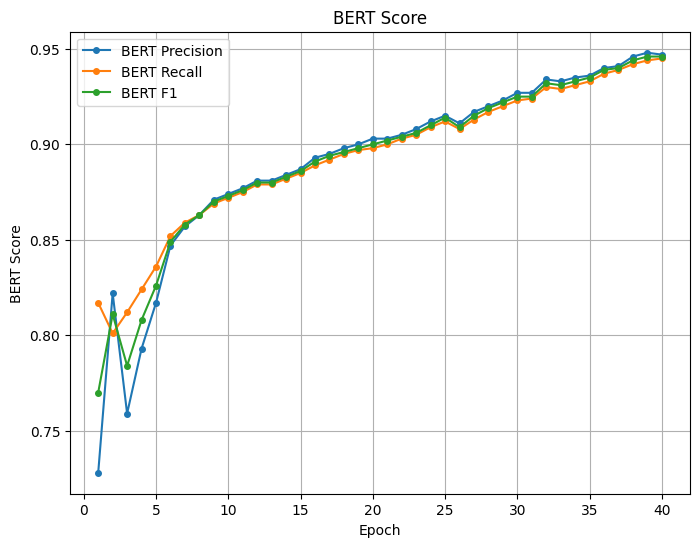

In [317]:
plot_bert_score(range(1, 40 + 1), val_bert_precision, val_bert_recall, val_bert_f1)

In [318]:
# torch.save(model.state_dict(), 'imgcap_last.pth')

[CLS] a bike riding a bike on a street . 

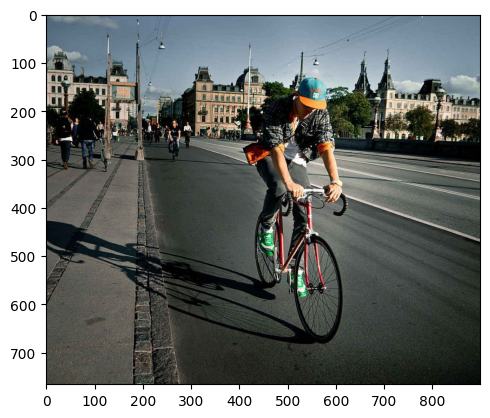

In [319]:
path = './test images/cycle.jpg'
get_image_caption(path)

[CLS] a person riding a bike parked on a bike . 

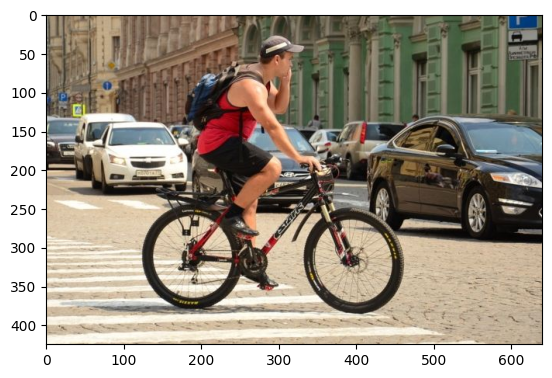

In [320]:
path = './test images/cycle_1.jpg'
get_image_caption(path)

[CLS] a person standing on a field with a frisbee . 

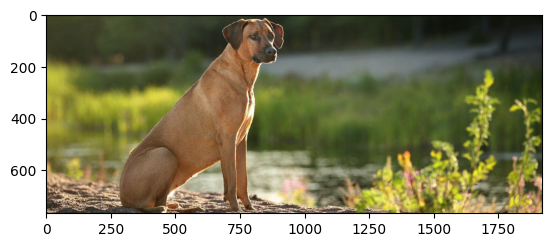

In [321]:
path = './test images/dog_1.jpg'
get_image_caption(path)

[CLS] a dog sitting on the side of a dog 

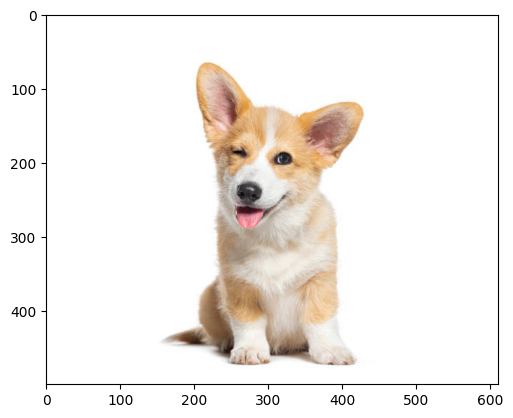

In [322]:
path = './test images/dog_2.jpg'
get_image_caption(path)

[CLS] a brown dog with two dogs in the back of 

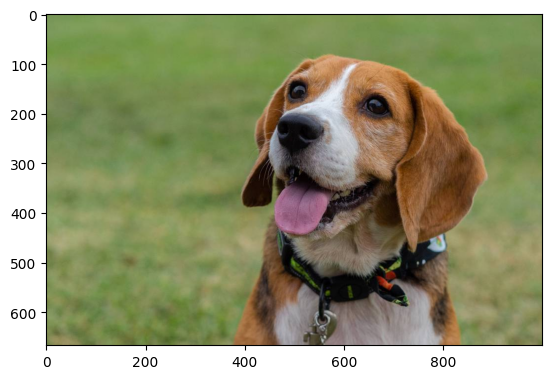

In [323]:
path = './test images/dog_3.jpg'
get_image_caption(path)

[CLS] a dog that is standing in the grass near a 

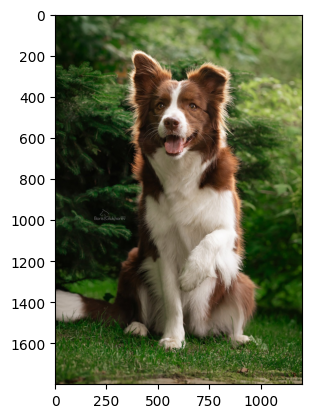

In [324]:
path = './test images/dog_4.jpg'
get_image_caption(path)

[CLS] a large plane flying in the air 

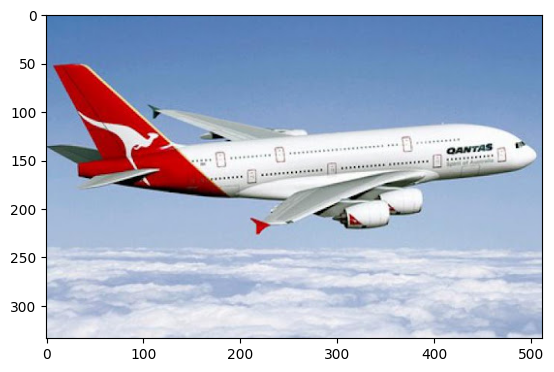

In [325]:
path = './test images/plane.jpg'
get_image_caption(path)

[CLS] a large plane flying in the air 

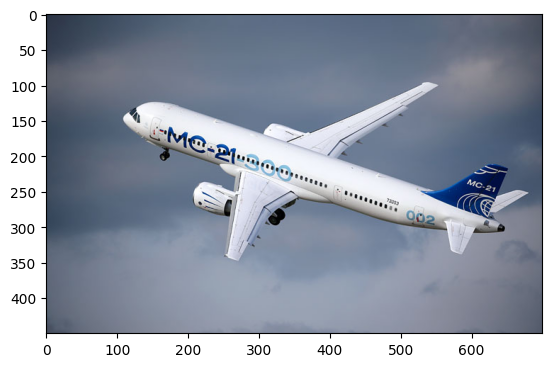

In [326]:
path = './test images/plane_1.jpg'
get_image_caption(path)

[CLS] a group of people standing on top of a dirt 

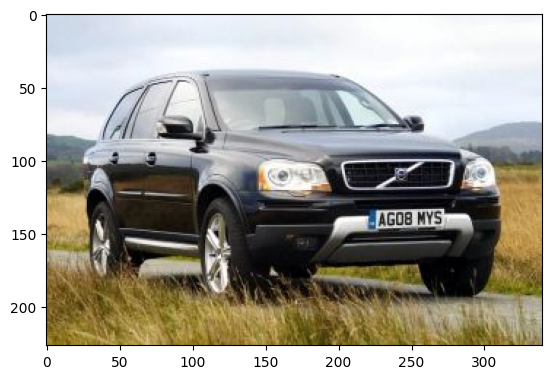

In [327]:
path = './test images/auto_1.jpg'
get_image_caption(path)

[CLS] a large white bus sitting in front of a car 

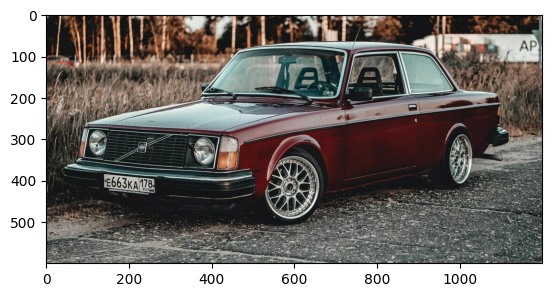

In [328]:
path = './test images/auto_2.jpg'
get_image_caption(path)

[CLS] a large motorcycle parked next to a car . 

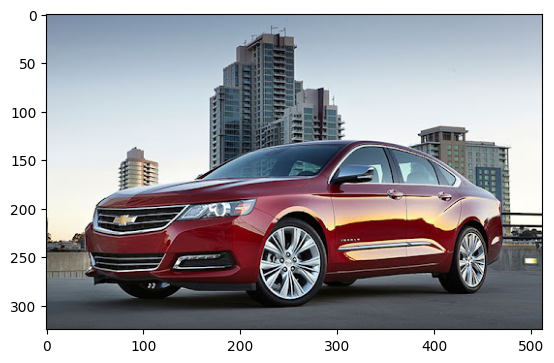

In [329]:
path = './test images/auto_3.jpg'
get_image_caption(path)

[CLS] a baseball player holding a baseball bat . 

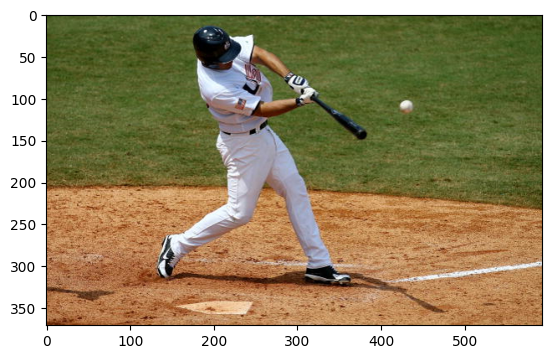

In [330]:
path = './test images/baseball_1.jpg'
get_image_caption(path)

[CLS] a baseball player holding a bat next to a baseball 

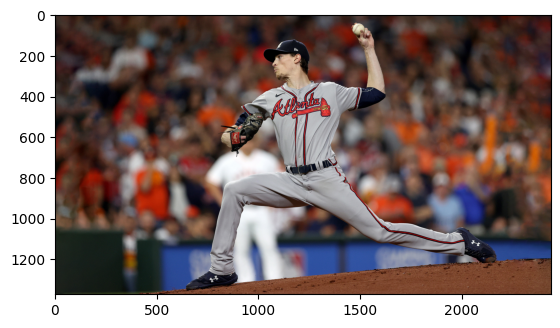

In [331]:
path = './test images/baseball_2.jpg'
get_image_caption(path)

[CLS] the bird is flying through the sky with sky . 

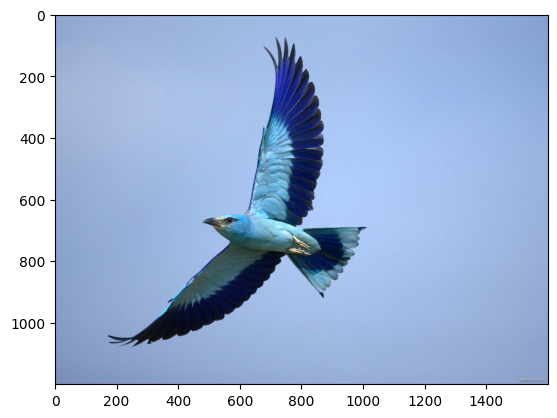

In [332]:
path = './test images/bird_1.jpg'
get_image_caption(path)

[CLS] a bird is flying through the sand . 

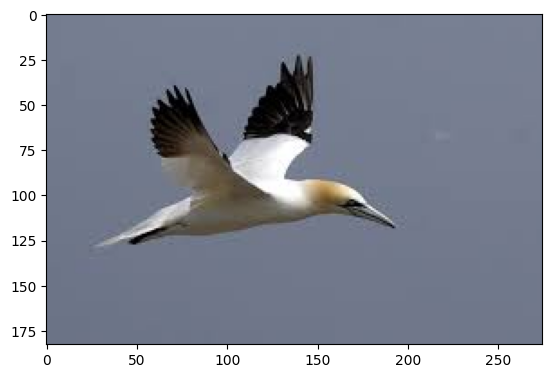

In [333]:
get_image_caption('./test images/bird_2.jpeg')

[CLS] a person holding a blue blue blue blue blue . 

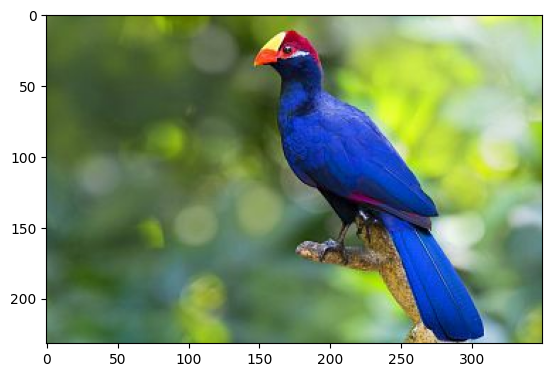

In [334]:
path = './test images/bird_3.jpg'
get_image_caption(path)

[CLS] a group of horse riding horses in the field . 

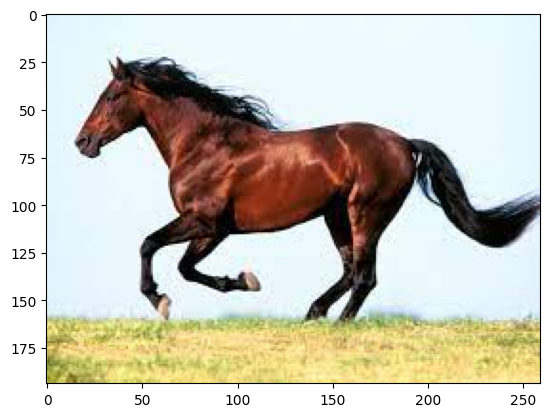

In [335]:
path = './test images/horse_1.jpeg'
get_image_caption(path)

[CLS] a horse standing next to a horse in a field 

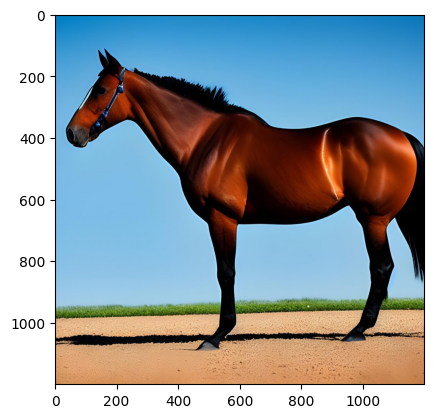

In [336]:
path = './test images/horse_2.jpeg'
get_image_caption(path)

[CLS] a person with a pizza is sitting on top of 

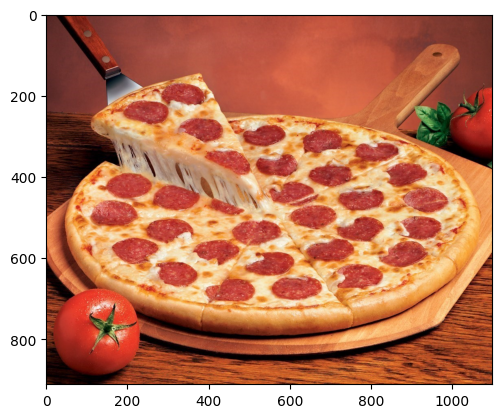

In [337]:
path = './test images/pizza_1.jpg'
get_image_caption(path)

[CLS] a pizza is sitting on a plate with pizza in 

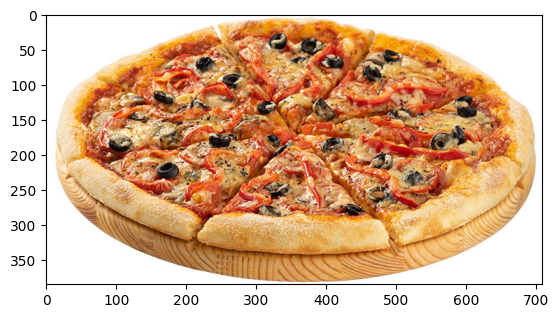

In [338]:
path = './test images/pizza_2.jpg'
get_image_caption(path)

[CLS] a close up of a person that has a plate 

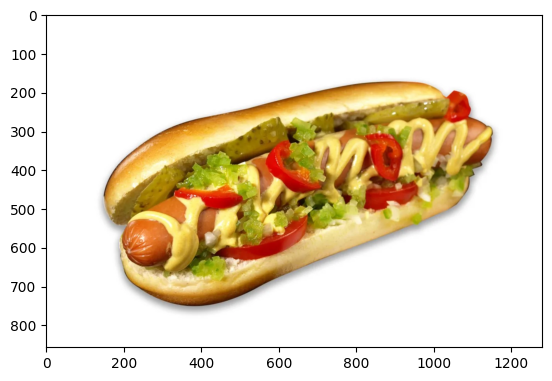

In [339]:
path = './test images/hot_dog_1.jpg'
get_image_caption(path)

[CLS] a person is on a plate with two dogs . 

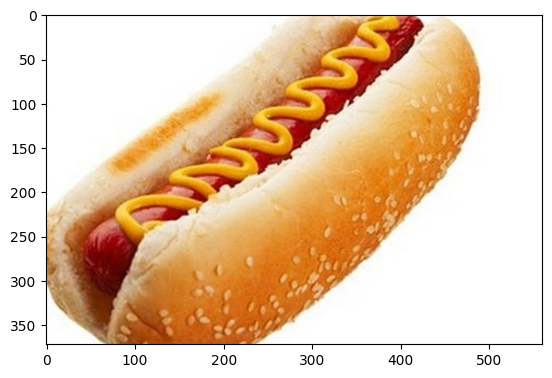

In [340]:
path = './test images/hot_dog_2.jpg'
get_image_caption(path)

[CLS] a young man riding a skateboard up a skateboard . 

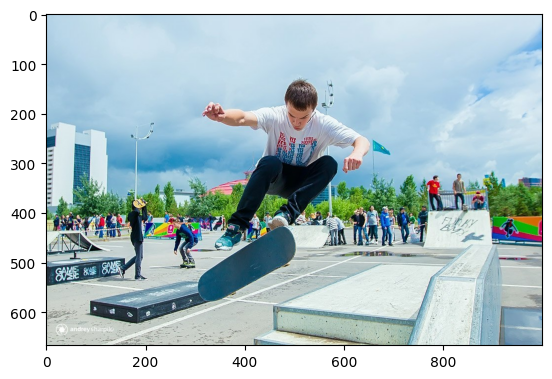

In [341]:
path = './test images/skateboard_1.jpg'
get_image_caption(path)

[CLS] a person on a skateboard doing a skateboard . 

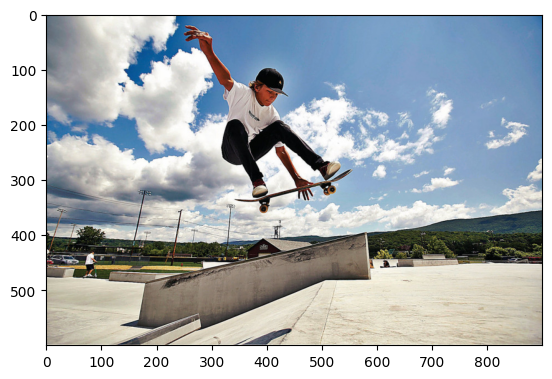

In [342]:
path = './test images/skateboard_2.jpg'
get_image_caption(path)

[CLS] a white plate topped with broccoli and broccoli . 

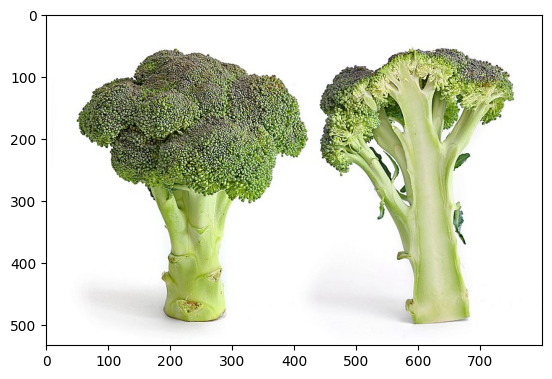

In [343]:
path = './test images/broccoli_1.jpg'
get_image_caption(path)

[CLS] a black plate topped with a broccoli and white plate 

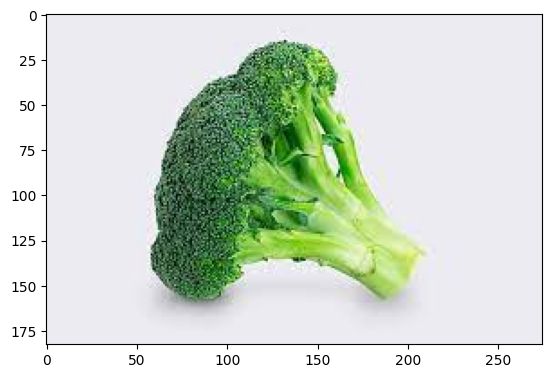

In [344]:
path = './test images/broccoli_2.jpeg'
get_image_caption(path)

[CLS] a refrigerator sitting on a wooden table next to a 

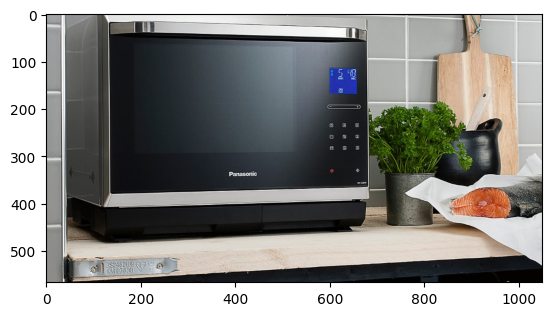

In [345]:
path = './test images/microwave_1.jpg'
get_image_caption(path)

[CLS] a person is holding a pizza on a plate on 

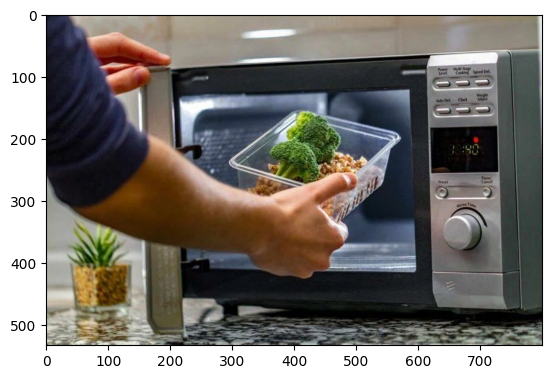

In [346]:
path = './test images/microwave_2.jpg'
get_image_caption(path)

[CLS] a large kitchen with various refrigerator , refrigerator . 

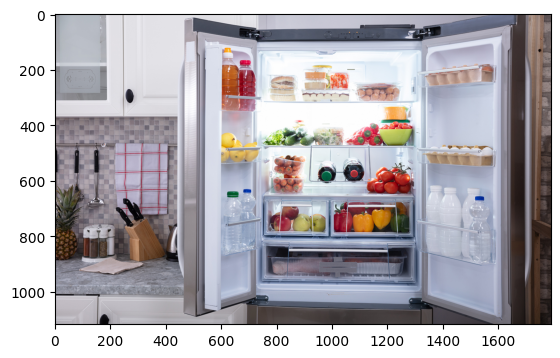

In [347]:
path = './test images/refrigerator_1.jpg'
get_image_caption(path)

[CLS] a refrigerator of kitchen with a refrigerator and refrigerator . 

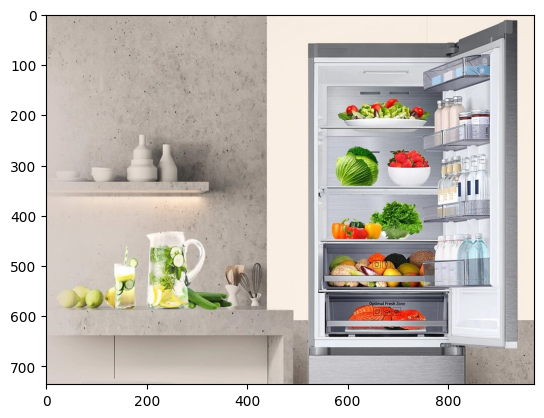

In [348]:
path = './test images/refrigerator_2.jpg'
get_image_caption(path)

[CLS] a cat sitting on top of a green green grass 

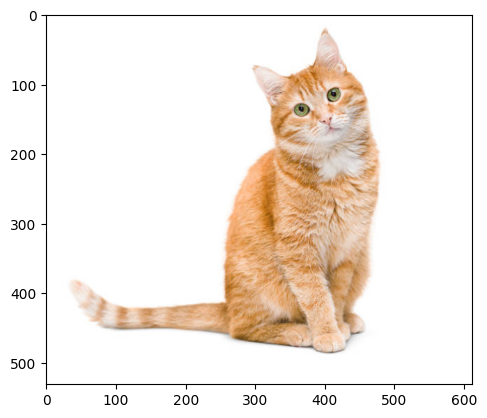

In [349]:
path = './test images/cat_1.jpg'
get_image_caption(path)

[CLS] a cat sitting in a field of a large building 

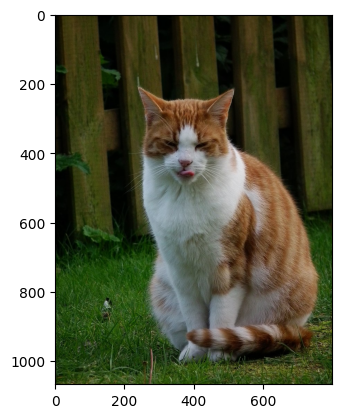

In [350]:
path = './test images/cat_2.JPG'
get_image_caption(path)

[CLS] a group of elephants walking across a field . 

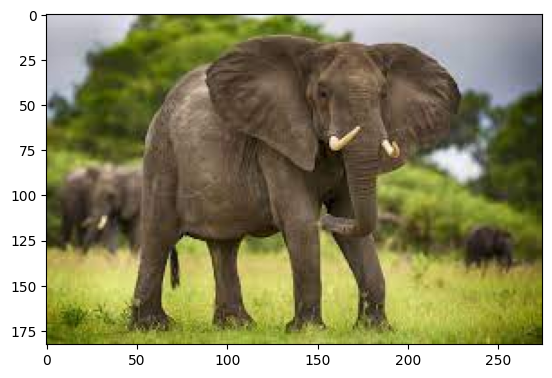

In [351]:
path = './test images/elephant_1.jpeg'
get_image_caption(path)

[CLS] two elephants in a field near a tree . 

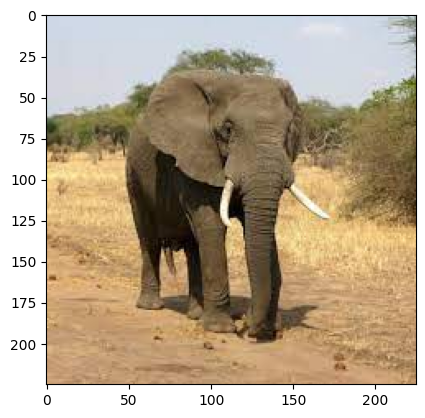

In [352]:
path = './test images/elephant_2.jpeg'
get_image_caption(path)

[CLS] a man riding a snowboard on a snow covered hill 

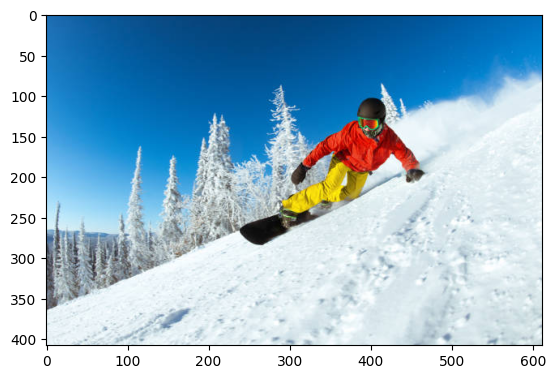

In [353]:
path = './test images/snowboard_1.jpg'
get_image_caption(path)

[CLS] a man riding skis on a snowy hill in snow 

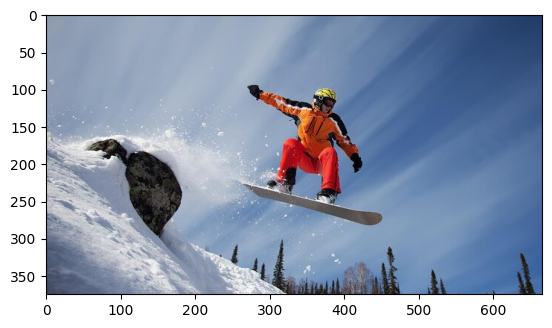

In [354]:
path = './test images/snowboard_2.jpg'
get_image_caption(path)

[CLS] a zebra standing next to each other in a large 

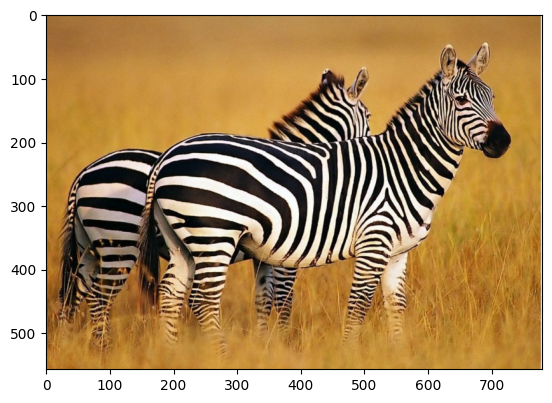

In [355]:
path = './test images/zebra_1.jpeg'
get_image_caption(path)

[CLS] two zebras standing in a field next to each other 

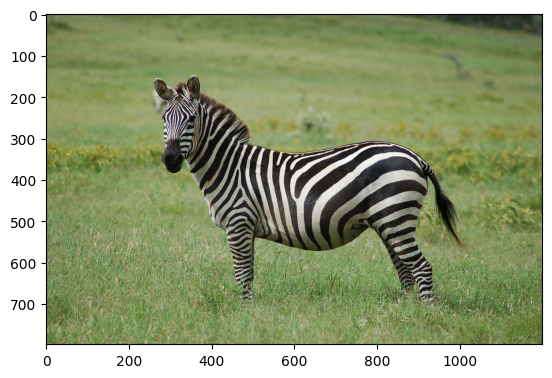

In [356]:
path = './test images/zebra_2.jpg'
get_image_caption(path)